# Tutorial 05: An optimization campaign
This notebook will guide you through an NSGA-II optimization campaign.
You will learn how to:
- choose the number of workers for your computer;
- set the variables, their bounds and the constraints;
- check a campaign before running it;
- run it, and read every candidate and the Pareto front;
- run one point of the front again, as a normal case.

What does a campaign do?
- It searches the operating conditions of a cycle for the best trade-off between two objectives, fixed in pyDAC:
  - the **equivalent work**: MJ per kg of recovered CO2, lower is better;
  - the **productivity**: kg of CO2 per m³ of bed per day, higher is better.
- Each candidate is the base case with its operating variables changed, run to its periodic state (CSS).
- The result is the **Pareto front**: the feasible candidates that no other candidate improves on one objective without being worse on the other.

This notebook runs a **trial**:
- 8 candidates per generation, for 4 generations: 32 CSS runs on a coarse 1D grid.
- It shows how a campaign is set up, checked, run and read.
- Note that its front is **not converged**.

A real campaign needs about 100 candidates for about 100 generations: ten thousand CSS runs.\
That belongs on a large machine, with as many free cores as you can give it.

### Overview
- **Case:** [`../cases/05_nsga2_trial.json`](../cases/05_nsga2_trial.json):
  the built-in cycle on a 1D grid of 25 cells, each step with its built-in stop rule.
- **Bounds:** [`../cases/05_nsga2_bounds.json`](../cases/05_nsga2_bounds.json).
- **Runtime:** about 3 minutes with 8 workers (about 20 minutes with one), plus two single CSS runs of under a minute each.
- **Memory and disk:** about 0.3 GB of memory per worker, under 100 MB on disk.
- **Same tutorial without a notebook:** the terminal commands at the end.

### Before you start
1. Install pyDAC and select its kernel, as in [tutorial 01](01_first_steps.ipynb).
2. Read [tutorial 03](03_css_tvsa.ipynb) first: a campaign runs many CSS runs like that one.
3. Check your free cores (next section) and set `WORKERS`.
4. Run the cells in order, from the top.

The results are written under `simulation_results/`, next to this notebook.

In [1]:
import os

# One numerical thread per worker. Set before numpy is imported: the workers run side by side,
# and a worker that starts several threads only slows the others down.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"

# Import necessary libraries
import json
import math
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

import pydac

# The base case and the bounds of the variables
CASE = Path("../cases/05_nsga2_trial.json")
BOUNDS = Path("../cases/05_nsga2_bounds.json")

## Cores and workers

A campaign runs several candidates at the same time:
- one per **worker**;
- each worker on one core of your computer.

This notebook uses **8 workers, so it needs at least 8 free cores**.\
With fewer, just lower `WORKERS` below: the campaign gives exactly the same result with any number of workers, it only takes longer.

How many cores do you have?

| System | Command (in a terminal) |
|---|---|
| Linux | `nproc` (logical cores); `lscpu` (physical cores = "Core(s) per socket" × "Socket(s)") |
| macOS | `sysctl -n hw.ncpu` (logical); `sysctl -n hw.physicalcpu` (physical) |
| Windows | `echo %NUMBER_OF_PROCESSORS%` in `cmd` (logical); Task Manager → Performance → CPU shows both |
| Python | `os.cpu_count()` (logical) |

Logical or physical?
- Logical cores count each hardware thread: with hyper-threading there are two per physical core.
- A CSS run makes best use of a whole physical core.

To choose the number of workers:
1. start from the number of **physical** cores;
2. keep one or two for the system and for this notebook;
3. subtract the cores that other programs, or other users of a shared machine, are using now:
   - Linux and macOS: the load average printed by `uptime` is about the number of busy cores;\
     `top` or `htop` shows who uses them;
   - Windows: the Task Manager;
4. check the memory: here each worker needs about 0.3 GB, a 2D case much more.

The cell below does not choose `WORKERS` for you: you set it, following the steps above.\
It prints your cores and how busy they are now, and warns you if `WORKERS` does not fit.

In [2]:
# Number of candidates run at the same time: lower it if you have fewer free cores
WORKERS = 8

# How many cores there are, and how many are busy now
cores = os.cpu_count()
try:
    busy = os.getloadavg()[0]  # Linux and macOS: about how many cores are busy now
except (AttributeError, OSError):
    busy = None  # Windows: see the Task Manager
print(f"logical cores: {cores}")
if busy is not None:
    print(f"busy now (1-minute load average): {busy:.1f}")

# Warn if WORKERS does not fit
free = cores - (busy or 0.0)
if free < WORKERS + 1:
    print(f"WARNING: fewer than {WORKERS + 1} free logical cores. Lower WORKERS: "
          "same result, longer run.")

logical cores: 48
busy now (1-minute load average): 0.5


## The base case

The campaign takes everything from the base case, except its operating variables.

This case is:
- the built-in steam-assisted TVSA cycle from [Tutorial 03](03_css_tvsa.ipynb) and [Tutorial 04](04_1d_vs_2d.ipynb);
- on a coarse 1D grid, so that each candidate takes well under a minute;
- with the built-in stop rule of each step:
  - adsorption, heating and desorption run for a fixed time, and the campaign variables set it;
  - blowdown, cooling and pressurization stop on their event: the vacuum level is reached,\
    the bed is back to 50 °C, the feed pressure is back.

With these options, the candidates print nothing and draw no plots, whatever the case says.


In [3]:
# Show the base case (a preset)
print(CASE.read_text())

{
  "schema_version": 8,
  "simulation": {
    "grid": {
      "nz": 25,
      "nr": 1
    }
  },
  "execution": {
    "plot_format": "png",
    "print_to_terminal": false,
    "print_cycle_build": false,
    "extra_tag": "tutorial_05"
  }
}



## The variables and their bounds

Which variables a campaign has depends on the desorption step of the cycle:
- with steam-assisted desorption (`s_des`, the built-in cycle) there are six, in the table below;
- with wall-heated desorption (`w_des`) there are five: the same, without `v_steam`.

| Variable | Unit | What it sets | Built-in value |
|---|---|---|---|
| `t_ads` | s | duration of adsorption (and startup) | 39000 |
| `t_heat` | s | duration of wall heating | 9000 |
| `t_des` | s | duration of steam-assisted desorption | 3600 |
| `P_vac` | Pa | the low pressure of the vacuum steps | 20000 |
| `v_feed` | m/s | air velocity in adsorption (feed flow / bed cross-section) | 0.068 |
| `v_steam` | m/s | steam velocity in desorption (at 100 °C and `P_vac`) | 0.59 |

The bounds file gives `[lower, upper]` for **every** variable of the cycle:
- pyDAC 3.0.0 always searches all of them;
- to study only *some* of them, give the others a **narrow** interval around the value you want.

Here we study three:
- `t_ads`, `t_heat` and `v_steam` move over a wide range;
- `t_des`, `P_vac` and `v_feed` stay within about 5 % of the built-in values.

In [4]:
# Show the bounds: [lower, upper] for every variable
print(BOUNDS.read_text())

{
  "t_ads": [10800, 43200],
  "t_heat": [3600, 10800],
  "t_des": [3420, 3780],
  "P_vac": [19000, 21000],
  "v_feed": [0.065, 0.072],
  "v_steam": [0.2, 0.8]
}



## Constraints

A constraint makes a candidate **infeasible** when it fails.\
The Pareto front is made of feasible candidates only.

pyDAC has five constraints:
- one is **always on**: a candidate whose run fails, or that does not reach CSS, is infeasible;
- four are **optional**, and all **off** by default: each option of `run_nsga2` turns one on.

| Option of `run_nsga2` | Terminal flag | A candidate is feasible when... | In this run |
|---|---|---|---|
| (none) | (none) | its run ends without errors and reaches CSS | always on |
| `purity_min` | `--purity-min` | the CO2 mole fraction of the product, water included, is at least this value | **on**: 0.95 |
| `oxygen_ppm_max` | `--oxygen-ppm-max` | the O2 in the product is at most this value, in ppm (molar) | **on**: 1000 |
| `eq_work_max` | `--eq-work-max` | the equivalent work is at most this value, in MJ per kg of CO2 | **on**: 60 |
| `steam_condensation=True` | `--steam-condensation` | at the end of `heat`, the coldest point of the bed is above the condensation temperature of the steam | off |

Two details:
- `oxygen_ppm_max` needs O2 in the mixture; `steam_condensation` needs H2O and a steam-assisted desorption (`s_des`).\
  Otherwise the campaign is refused before it starts.
- "Reaches CSS" follows `execution.require_css` (on by default): with it off, a candidate that stops at `execution.max_cycles` still counts.

Why these choices for this run?
- `eq_work_max=60` is the one that matters here: it keeps the most expensive cycles out of the front.
- Purity and O2 are the safeguards of a real campaign: other cycles, sorbents or bounds can break them.
- `steam_condensation` stays off: none of the candidates of this trial came closer than 13 K to condensation,\
  so it would change nothing.

Every candidate record keeps the value of each constraint, under `constraints` (feasible when the value is at most 0).\
The always-on one is called `valid_evaluation_and_css`.

## Check before running

`run_nsga2` checks the case, the bounds and the campaign folder before it starts anything.

It also builds the two corner candidates of the box:
- every variable at its lower bound;
- every variable at its upper bound.

Bounds that make a corner impossible are refused.\
For example, an adsorption longer than the startup step's time limit (43200 s):

In [5]:
# Widen t_ads beyond the startup time limit, and try to start: we expect a refusal
wide = json.loads(BOUNDS.read_text()) | {"t_ads": [10800, 50000]}
try:
    pydac.run_nsga2(pydac.load_case(CASE), wide, pop_size=8, generations=4, workers=WORKERS)
except pydac.ConfigurationError as error:
    print(error)

Candidates at the upper bounds (t_ads=50000, t_heat=10800, t_des=3780, P_vac=21000, v_feed=0.072, v_steam=0.8) cannot run: Invalid configuration for step `startup`: `event_max_time_s` cannot be shorter than nominal time. Adjust the bounds or the base case.


Nothing was solved and nothing was written.

From the terminal, `pydac nsga2 ... --dry-run` runs the same checks and prints the campaign folder\
(see the end of this notebook).

## Run the campaign

A campaign never writes into a folder that already holds one:
- running the same campaign again is refused, once it has finished its first generation (shown below);
- so the first lines remove this notebook's campaigns from earlier runs;
- this way you can run the notebook again from the top.

How does the cell find them? A campaign folder starts with the `execution.extra_tag` of its case,\
here `tutorial_05` (see the case above), then the grid and the bed: `tutorial_05_1D_25z_packed_bed_`.\
The cell removes only the folders that start with exactly that: your other campaigns in `simulation_results/nsga2/` stay.

In [6]:
# Remove this notebook's campaigns from earlier runs, if any:
# their folders start with the tag, the grid and the bed, "tutorial_05_1D_25z_packed_bed_"
for old in Path("simulation_results/nsga2").glob("tutorial_05_1D_25z_packed_bed_*"):
    if old.is_dir() and not old.is_symlink():  # only folders
        shutil.rmtree(old)

# The base case and the campaign options: size and constraints
case = pydac.load_case(CASE)
options = dict(pop_size=8, generations=4, purity_min=0.95, oxygen_ppm_max=1000, eq_work_max=60)

# Run the campaign and print its folder
campaign = pydac.run_nsga2(case, BOUNDS, workers=WORKERS, **options)
print(campaign.folder)

Campaign folder: /path/to/pyDAC/examples/notebooks/simulation_results/nsga2/tutorial_05_1D_25z_packed_bed_ac074b54

                                                Starting NSGA-II Optimization                                           

  Decision variables (6): ['t_ads', 't_heat', 't_des', 'P_vac', 'v_feed', 'v_steam']
  Objectives:         2  (eq_work ↓, productivity ↑)
  Constraints (4):    ['valid_evaluation_and_css', 'purity_min', 'oxygen_ppm_max', 'eq_work_max']
  Cycle steps:        ['ads', 'blow', 'heat', 's_des', 'cool', 'press']
  Desorption mode:    s_des
  Bed architecture:   packed_bed
  Composition guard:  {'enabled': True, 'absolute_allowance_mol_m3': 2.0, 'relative_allowance': 0.1}
  Persistence:       moo_compact (ordinary candidates)
  tau_ar=0.5,  bed_volume=0.001
  adsorption_T_feed=298.15 K,  adsorption_RH=0.5
  equilibrium_systems=('TothGABWADST',),  max_cycles=50,  css_tol=0.005

  Population size:    8
  Generations:        4
  Termination:        fixed_generat

The campaign printed one line per generation, and a summary.

Its folder name holds:
- the `execution.extra_tag` of the case, `tutorial_05`;
- the grid and the bed;
- a hash of the whole campaign definition: base case, bounds, constraints, population, generations, seed;
- but not the number of workers.

You can find all the results of the campaign in its folder (printed above, `campaign.folder`):
- `resolved_config.json`: the base case;
- `results/` (in Python, `campaign.results_folder`):
  - `candidate_records/`: the record of every candidate (next section);
  - `pareto_front.csv`: the Pareto front (read below);
  - `figures/`: the front and the distribution of the variables, as PDF;
  - `optimization_summary.json`: the final summary, with every error;
  - `checkpoint_state.json` and `checkpoints/`: what `resume` reads;
- `generation_log.txt` and `evaluations_log.txt`: the progress logs;
- `gen_04/`: the run folders of the last generation (those of the earlier generations are deleted as the campaign goes on).

## Every candidate

Each candidate leaves one record in `results/candidate_records/` (one file per generation):
- its variables;
- its objectives;
- its constraint values (feasible when every value is at most 0);
- its CSS history;
- if its run failed, the error.

To see what the trial found, we put all the records in one table.\
The next cell reads every record and keeps one row per candidate:
- its generation and its six variables;
- its two objectives;
- the purity and the O2 of its product, and the cycle at which it reached CSS;
- whether it is feasible (every constraint value at most 0);
- its error, if its run failed (then the columns of the results are empty).

In [7]:
# Read all the records, generation by generation
records = []
for path in sorted((campaign.results_folder / "candidate_records").glob("generation_*.jsonl")):
    with open(path) as handle:
        records += [json.loads(line) for line in handle]

# One row per candidate: variables, objectives, purity, O2, CSS cycle, feasible, error
rows = []
for record in records:
    row = {"generation": record["generation"], **record["decision_vector"]}
    if record["failure"] is None:
        row["equivalent work [MJ/kg]"] = record["objectives"]["eq_work_MJ_per_kgCO2"]
        row["productivity [kg/m3/day]"] = -record["objectives"]["neg_productivity_kgCO2_per_m3_day"]
        row["purity, wet [%]"] = 100 * record["metrics"]["purity_wet"]
        row["O2 [ppm]"] = record["metrics"]["oxygen_ppm"]
        row["CSS at cycle"] = record["css"]["cycles_completed"]
    row["feasible"] = max(record["constraints"].values()) <= 0
    row["error"] = None if record["failure"] is None else str(record["failure"])
    rows.append(row)
candidates = pd.DataFrame(rows)
print(f"{len(candidates)} candidates, {(~candidates['feasible']).sum()} infeasible, "
      f"{candidates['error'].notna().sum()} failed")
candidates.round(3)

32 candidates, 12 infeasible, 0 failed


,generation,P_vac,t_ads,t_des,t_heat,v_feed,v_steam,equivalent work [MJ/kg],productivity [kg/m3/day],"purity, wet [%]",O2 [ppm],CSS at cycle,feasible,error
0,1,20990.258,18463.794,3674.645,9238.379,0.069,0.215,50.296,31.618,96.833,0.0,3,True,None
1,1,19967.399,12396.222,3523.678,7906.454,0.066,0.676,314.788,18.570,96.833,0.0,3,False,None
2,1,20310.367,26977.621,3432.316,4939.636,0.068,0.734,121.086,36.400,96.833,0.0,3,False,None
3,1,20241.460,19887.358,3581.334,5470.209,0.072,0.403,84.890,35.112,96.833,0.0,3,False,None
4,1,19436.878,38980.744,3486.655,10702.656,0.071,0.444,56.434,31.597,96.833,0.0,2,True,None
5,1,19072.592,27588.547,3718.322,8224.164,0.070,0.564,87.840,35.319,96.833,0.0,3,False,None
6,1,20701.831,42387.758,3633.050,6616.836,0.067,0.349,42.812,36.216,96.833,0.0,2,True,None
7,1,19695.614,33324.807,3768.988,4457.457,0.066,0.641,90.148,38.955,96.833,0.0,2,False,None
8,2,20701.831,43095.653,3633.050,6616.836,0.067,0.347,42.600,35.781,96.833,0.0,2,True,None
9,2,19072.592,18251.080,3674.892,8205.731,0.069,0.211,45.303,32.879,96.833,0.0,3,True,None


What the table tells us:
- **No candidate failed** here. When one does:
  - its row has an `error`, and the campaign carries on;
  - the final summary lists the most frequent errors;
  - `results/optimization_summary.json` keeps all of them.
- **The 12 infeasible candidates** all exceed the 60 MJ/kg limit.
- **The purity and the O2 constraints** are met by every candidate, by a wide margin.
  - In this cycle the vacuum blowdown removes the air before the product is collected.
  - So the product is CO2 and the water vapour left after the condenser.
  - They are the safeguards of a real campaign, where other cycles, sorbents or bounds can break them.

## The Pareto front

`results/pareto_front.csv` holds the front, one row per point:
- the variables;
- the flows they give in the model;
- the two objectives: `eq_work` (MJ/kg) and `productivity` (kg/m³/day).

In [8]:
# Read the front and show the variables and the objectives
front = pd.read_csv(campaign.results_folder / "pareto_front.csv")
front[["t_ads", "t_heat", "v_steam", "t_des", "P_vac", "v_feed", "eq_work", "productivity"]].round(3)

,t_ads,t_heat,v_steam,t_des,P_vac,v_feed,eq_work,productivity
0,43122.061,6318.039,0.274,3626.995,20701.831,0.067,33.243,36.538
1,39019.345,8205.731,0.203,3650.336,19072.592,0.069,25.578,35.100
2,38871.948,8207.349,0.211,3650.336,19006.078,0.070,26.354,35.362


### The default cycle, for comparison

How far did the search go?\
To see it, we need the starting point: the base case itself, the built-in cycle, run once to CSS without any change.

First, a small function that reads the two objectives of a CSS run from its folder\
(with `CycleDataLoader` and `CycleKPIs`, as in [tutorial 03](03_css_tvsa.ipynb)):

In [9]:
def objectives(result):
    # Equivalent work [MJ/kg] and productivity [kg/m3/day] of a CSS run
    kpis = pydac.CycleKPIs(pydac.CycleDataLoader(result.folder).load())
    return kpis.equivalent_work(), kpis.productivity()

Then we run the base case `case` (the one the campaign started from) to CSS, as in [tutorial 03](03_css_tvsa.ipynb), and print its objectives.\
It takes under a minute. pyDAC prints its run folder, the files it saves and the KPI summary of the cycle\
(as in [tutorial 03](03_css_tvsa.ipynb)); the last line gives the two objectives.

In [10]:
# Run the base case, unchanged, to CSS: this is the built-in cycle
# (overwrite=True replaces the run of an earlier session of this notebook)
builtin_run = pydac.run_css(case, overwrite=True)

# Its two objectives
builtin = objectives(builtin_run)
print(f"built-in cycle: {builtin[0]:.1f} MJ/kg, {builtin[1]:.1f} kg/m3/day")

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1
Post-processing cycle 3.
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_y_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_y_H2O.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_y_O2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_y_N2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_q_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_967a5cd1/1D_mode/plots_css/cycle_3/css_outlet_q_H2O.png
[Saved] simulation_results/cyclic_mode/tutor

### All the candidates in one figure

The next cell draws the two objectives of every candidate, one against the other:
- productivity on the x axis (higher is better), equivalent work on the y axis (lower is better):\
  the best cycles are at the **bottom right**;
- blue dots: the feasible candidates;
- grey crosses: the infeasible ones, all above the 60 MJ/kg limit (dotted line);
- red circles: the Pareto front;
- black star: the built-in cycle.

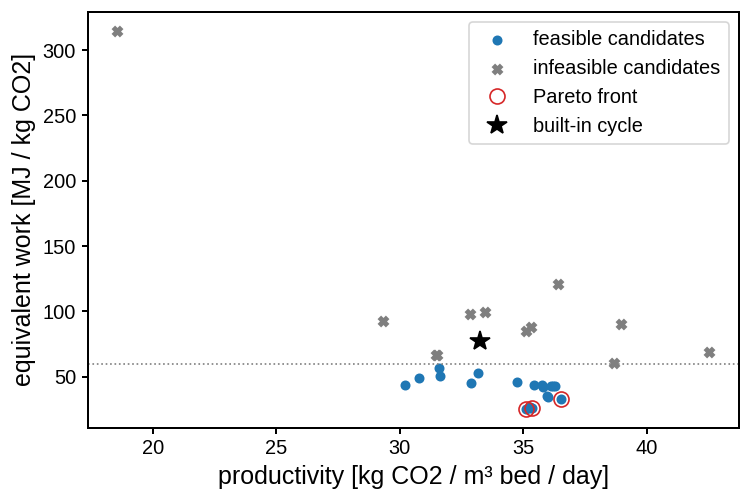

In [11]:
# Every candidate that ran, feasible or not
done = candidates.dropna(subset=["equivalent work [MJ/kg]"])
fig, ax = plt.subplots(figsize=(7, 4.5))
for feasible, style in [(True, dict(color="tab:blue", label="feasible candidates")),
                        (False, dict(color="tab:gray", marker="x", label="infeasible candidates"))]:
    subset = done[done["feasible"] == feasible]
    ax.scatter(subset["productivity [kg/m3/day]"], subset["equivalent work [MJ/kg]"], s=25, **style)

# The front (red circles), the built-in cycle (star) and the 60 MJ/kg limit (dotted)
ax.plot(front["productivity"], front["eq_work"], "o", color="tab:red", markersize=9,
        markerfacecolor="none", label="Pareto front")
ax.plot(builtin[1], builtin[0], "*", color="black", markersize=12, label="built-in cycle")
ax.axhline(60, color="tab:gray", linestyle=":", linewidth=1)
ax.set_xlabel("productivity [kg CO2 / m³ bed / day]")
ax.set_ylabel("equivalent work [MJ / kg CO2]")
ax.legend()
plt.show()

What the front tells us:
- In 32 runs the search already finds cycles that, compared with the built-in one:
  - need about a third of the equivalent work (26 to 33 against 77 MJ/kg);
  - are 6 to 10 % more productive.
- How? Mainly:
  - about a third of the steam (`v_steam` 0.20 to 0.27 m/s instead of 0.59);
  - a shorter wall heating (6300 to 8200 s instead of 9000);
  - an adsorption as long as the built-in one or longer, up to the upper bound.

Read the front as a direction, not as an answer:
- with 8 candidates per generation and 4 generations it is far from converged;
- its three points lie close to each other;
- a real campaign spreads the front over the whole range of productivity.

The campaign also wrote the front and the distribution of the variables as PDF figures, in `results/figures/`.\
`pydac nsga2 --report CAMPAIGN` writes them again.

## A campaign is not run twice, and does not grow

Running the same campaign again is refused, because its folder already holds it:

In [12]:
# Same campaign again: we expect a refusal
try:
    pydac.run_nsga2(case, BOUNDS, workers=WORKERS, **options)
except pydac.ConfigurationError as error:
    print(error)

simulation_results/nsga2/tutorial_05_1D_25z_packed_bed_ac074b54 already holds committed generations of this campaign; continue it with --resume, or change the seed or output root for a new one.


`pydac.resume` continues a campaign that was interrupted (Ctrl+C, a crash, a reboot):
- from its last finished generation;
- up to the number of generations it was started with.

Stopped before its first generation finished? Then nothing was saved to continue:\
start the same campaign again, with the same call (`resume` would refuse it).

This one is complete, so it is refused:

In [13]:
# Resume a complete campaign: we expect a refusal
try:
    pydac.resume(campaign.folder, workers=WORKERS)
except pydac.ConfigurationError as error:
    print(error)

Campaign already completed 4 of 4 requested generations.


Want more generations? Start a new campaign with a larger `generations`.
- It gets a new folder.
- It starts again from the first generation.

A real campaign is started once with its full size,\
and continued with `resume` after each interruption\
(or started again, if it stopped inside its first generation).

## Run one point of the front as a normal case

Each record keeps the complete case of its candidate, under `provenance.input.resolved_config`.
- Saved to a file, it is an ordinary frozen case!
- Run it to CSS to get the plots and KPIs from [Tutorial 03](03_css_tvsa.ipynb).

Two details:
- The campaign saves no step profiles, so the cell switches the plot setting on for the reported cycle.
- An output setting changes the fingerprint (a new run folder), not the numbers.

Here we take the front point with the lowest equivalent work:

In [14]:
# The front point with the lowest equivalent work, and its record
best = front.loc[front["eq_work"].idxmin()]
variables = ["t_ads", "t_heat", "t_des", "P_vac", "v_feed", "v_steam"]
record = next(r for r in records
              if all(math.isclose(r["decision_vector"][name], best[name], rel_tol=1e-12)
                     for name in variables))

# Its complete case, with two output options changed, saved as a frozen case
config = record["provenance"]["input"]["resolved_config"]
config["execution"]["output_root"] = "simulation_results"  # the record says ".": where you run it
config["execution"]["plot_final_cycle_profiles"] = True    # step profiles of the reported cycle
best_case = Path("output_cases/05_best_case.json")
best_case.parent.mkdir(exist_ok=True)  # create output_cases/ if it is missing
best_case.write_text(json.dumps(config, indent=2))

# Run it to CSS (the comparison is in the next cell)
rerun = pydac.run_css(pydac.load_case(best_case, exact=True), overwrite=True)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962


Post-processing cycle 3.
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_y_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_y_H2O.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_y_O2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_y_N2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_q_CO2.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_q_H2O.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_T_bed.png
[Saved] simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962/1D_mode/plots_css/cycle_3/css_outlet_T_wall.png
[Saved] simulation_results/cycli

In [15]:
# Compare the rerun with the campaign: the same case gives the same numbers
work, productivity = objectives(rerun)
print("Best point: campaign vs rerun")
print("=" * 60)
print(f"{'':10s} {'eq. work [MJ/kg]':>18s} {'productivity [kg/m3/day]':>26s}")
print(f"{'campaign':10s} {best['eq_work']:18.4f} {best['productivity']:26.4f}")
print(f"{'rerun':10s} {work:18.4f} {productivity:26.4f}")
print("=" * 60)
print(f"run folder: {rerun.folder}")

Best point: campaign vs rerun
             eq. work [MJ/kg]   productivity [kg/m3/day]
campaign              25.5779                    35.0998
rerun                 25.5779                    35.0998
run folder: /path/to/pyDAC/examples/notebooks/simulation_results/cyclic_mode/tutorial_05_packed_bed_d87f5962


Now you can inspect its run folder; it holds the step profiles of the cycle and its KPI report ([Tutorial 03](03_css_tvsa.ipynb) shows how to read them).

## From a trial to a real campaign

- **Size**: `pop_size` and `generations` of about 100 each.
  - Or `termination="robust_pareto"`, which stops when the front stops moving\
    (guide: [Optimization campaigns](../../docs/guide/05_optimization.md)).
- **Grid**: fine enough for the KPIs you compare; check it on single CSS runs first.
- **Bounds**: wide on every variable you want to optimize.
- **Constraints**: the limits your design needs.
  - The [pyDAC paper](https://doi.org/10.26434/chemrxiv.15010382/v1) uses `purity_min=0.95`, `oxygen_ppm_max=40`, `eq_work_max=30` and `steam_condensation=True`.
- **Where**:
  - 10 000 CSS runs of about half a minute, as on this coarse 1D grid, take about half a day on 8 cores;
  - on a 2D grid like the one in [Tutorial 03](03_css_tvsa.ipynb) (about 10 minutes each), they take about 1 700 core-hours:\
    more than a day, even on a 64-core workstation!
  - So run it on the largest machine you have:
    - start it from a script, with `if __name__ == "__main__":`;
    - give it as many workers as free cores;
    - continue it with `resume` if it stops.

## The same from the terminal

Run these from the folder of this notebook, in place of the cells above.\
After the notebook the campaign already exists: the first two commands are refused, as shown above; the third works.

```bash
# 1. Check everything and print the campaign folder (nothing is solved)
pydac nsga2 --config ../cases/05_nsga2_trial.json --bounds ../cases/05_nsga2_bounds.json --pop-size 8 --generations 4 --purity-min 0.95 --oxygen-ppm-max 1000 --eq-work-max 60 --workers 8 --dry-run

# 2. Run the campaign
pydac nsga2 --config ../cases/05_nsga2_trial.json --bounds ../cases/05_nsga2_bounds.json --pop-size 8 --generations 4 --purity-min 0.95 --oxygen-ppm-max 1000 --eq-work-max 60 --workers 8

# 3. Write its figures and pareto_front.csv again
pydac nsga2 --report simulation_results/nsga2/tutorial_05_1D_25z_packed_bed_ac074b54
```

Before the second command, set one thread per worker in the shell:\
`export OMP_NUM_THREADS=1 OPENBLAS_NUM_THREADS=1 MKL_NUM_THREADS=1` (Linux and macOS).

**Previous:** [Tutorial 04: 1D or 2D](04_1d_vs_2d.ipynb).\
**Next:** [Tutorial 06: Reproduce the breakthrough validation](06_breakthrough_validation.ipynb).